![Banner](../images/09_capstones.png)

# Micronutrient Deficiency Mapping in Bangladesh Soils

**A geostatistical capstone: indicator kriging, regression with spatial residuals, and survey-unit effects**

This is Capstone 6 of the geostatistics module (Part 9). It maps where the soils of Bangladesh are likely to be deficient in zinc (Zn), boron (B) and sulphur (S), the three micronutrients most often limiting rice-based cropping, and turns the maps into upazila-level advice on where blanket application is justified.

**Data:** 37,923 georeferenced topsoil samples with soil-test values and landscape attributes (`Data/00_shared/data_geostatistics/BD_Data/bd_soil.csv`), a 500 m landscape grid (`bd_grid.csv`), and the national boundary in BUTM (`BD_Banladesh_BUTM.shp`).

**Targets:** P(Zn < 0.6 µg/g), P(B < 0.2 µg/g), P(S < 10 µg/g), and the probability that at least one of the three is deficient.

**Library:** `geolattice.geostatistics` (`IndicatorKriging`, `fit_indicator_variogram`), with scikit-learn random forests.

## Overview

Zinc, boron and sulphur deficiencies became widespread in Bangladesh as intensive rice cropping (two or three crops a year, high-yielding varieties) removed more nutrients than were returned. The Fertilizer Recommendation Guide of the Bangladesh Agricultural Research Council (BARC) interprets soil tests against critical levels: below them a crop is expected to respond to the nutrient. A deficiency map tells extension services where to recommend Zn, B or S, and where blanket application wastes money.

A deficiency map is a probability map. Indicator kriging (IK) codes each sample as 1 if it is below the critical level and 0 otherwise, and kriges the indicator, which estimates the local probability of deficiency without assuming a distribution for the nutrient. Two other ideas are compared with it: a random forest that predicts deficiency from landscape attributes (agro-ecological zone, land type, drainage, cropping pattern, geology, elevation), and a random forest whose residuals are kriged.

A national data set built from many local surveys also raises a question that a textbook example does not: do the survey units themselves leave a mark on the data? Section 3 shows that they do, and Sections 4 and 5 use that finding.

### Objectives

| Objective | Question | Sections |
|---|---|---|
| 1. Prepare the data | What coordinate system are the samples in, and which values are censored or duplicated? | 1 |
| 2. Describe deficiency | How common is each deficiency, and how does it vary with landscape, pH and organic matter? | 2 |
| 3. Spatial structure | Over what distance are deficiencies correlated, and do upazila boundaries matter? | 3 |
| 4. Compare methods | Which estimator predicts deficiency best, at what distance from a sample, and how well calibrated is it? | 4 |
| 5. Map | What do the probability maps look like on a 1 km grid? | 5 |
| 6. Combine and decide | Where is more than one nutrient deficient, and which upazilas warrant blanket application? | 6 and 7 |

### Critical levels

| Nutrient | Critical level (µg/g) | Deficient if |
|---|---|---|
| Zn | 0.6 | Zn < 0.6 |
| B | 0.2 | B < 0.2 |
| S | 10 (14 in FRG 2018, used as a sensitivity check) | S < 10 |
| Cu | 0.2 | Cu < 0.2 |
| Fe | 4.0 | Fe < 4.0 |

These are the critical levels of the BARC Fertilizer Recommendation Guide as quoted in Bangladeshi field studies (for example Sultana et al., 2016; Naher et al., 2024). The extraction methods of the soil tests are not documented in the data folder, so the levels are applied as given.

## Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Inline figures and the libraries for maps, indicator kriging, and random forests
%matplotlib inline
import sys, time, warnings
warnings.filterwarnings("ignore")
sys.modules.setdefault("tensorflow", None)

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import pyproj
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.optimize import least_squares
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import roc_auc_score, brier_score_loss

# Indicator kriging from geolattice, and a check for a usable GPU
import geolattice.geostatistics as gstat
from geolattice.geostatistics import IndicatorKriging, fit_indicator_variogram
from geolattice.geostatistics.utils.backend import cupy_gpu_usable

# Figure style, wide table display, and the seed for the forests and the variogram subset
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 160)
SEED = 42
USE_GPU = cupy_gpu_usable()
print("geolattice.geostatistics :", gstat.__version__)
print("Backend             :", "GPU (CuPy)" if USE_GPU else "CPU (NumPy)")

# Critical levels for Zn, B, and S. Copper and iron levels are used in the data checks.
CL = {"ZN": 0.6, "B": 0.2, "S": 10.0}          # critical levels (µg/g)
CL_OTHER = {"CU": 0.2, "FE": 4.0}
NAME = {"ZN": "Zn", "B": "B", "S": "S", "ANY": "Zn, B or S"}
K = 32                                          # kriging neighbours
N_TREES = 100                           # trees per random forest
GRID_KM = 1.0                                   # prediction grid spacing
MAX_DIST_KM = 5.0                               # grid nodes farther than this from a sample are not mapped

geolattice.geostatistics : 0.3.49
Backend             : GPU (CuPy)


## Data

### Coordinate system

The sample and grid coordinates (`x`, `y`) are in metres, but not in the BUTM system of the boundary file. The samples also carry longitude and latitude, which makes it possible to identify the system. The coordinates match the Lambert conformal conic projection of India zone IIb on the Kalianpur 1975 datum (EPSG:24380), with the false easting and northing shifted by +846 m and +3,066 m. The check below projects the samples to BUTM with that definition and compares them with the BUTM position of their longitude and latitude.

In [2]:
# Walk up from the working directory until the soil table is found
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "data_geostatistics" / "BD_Data" / "bd_soil.csv").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find Data/00_shared/data_geostatistics/BD_Data/bd_soil.csv. "
                                "Run this notebook from the GeoLattice repository.")
    ROOT = ROOT.parent
DATA = ROOT / "Data" / "00_shared" / "data_geostatistics" / "BD_Data"

# The boundary is in BUTM. Sample x, y are a shifted Kalianpur Lambert system.
boundary = gpd.read_file(DATA / "BD_Banladesh_BUTM.shp")
BUTM = boundary.crs
NATIVE = pyproj.CRS.from_proj4(
    "+proj=lcc +lat_1=26 +lat_0=26 +lon_0=90 +k_0=0.99878641 +x_0=2744041.5 +y_0=917464.2 "
    "+a=6377299.151 +rf=300.8017255 +towgs84=295,736,257,0,0,0,0 +units=m +no_defs")
to_butm = pyproj.Transformer.from_crs(NATIVE, BUTM, always_xy=True)
ll_to_butm = pyproj.Transformer.from_crs("EPSG:4326", BUTM, always_xy=True)

# Project stored x, y and lon/lat into BUTM. latin-1 keeps place names that are outside UTF-8.
raw = pd.read_csv(DATA / "bd_soil.csv", encoding="latin-1")
X, Y = to_butm.transform(raw["x"].to_numpy(), raw["y"].to_numpy())
X0, Y0 = ll_to_butm.transform(raw["Longitude (I)"].to_numpy(), raw["Latitude (I)"].to_numpy())
err = np.hypot(X - X0, Y - Y0)
print(f"Samples: {len(raw):,}")
print(f"Distance between projected x, y and projected lon, lat: median {np.median(err):.1f} m, max {err.max():.1f} m")
raw["X"], raw["Y"] = X / 1000, Y / 1000          # BUTM, km

Samples: 37,923
Distance between projected x, y and projected lon, lat: median 2.6 m, max 10.2 m


### Cleaning

- **Duplicates.** Samples with identical coordinates are dropped.
- **Zeros.** B is reported in steps of 0.1 µg/g and has many values of 0.0, which mean below 0.05. They count as deficient. Zeros in the other nutrients are rare.
- **Censoring at the top.** Fe is capped at 500 and Mn at 100 µg/g. The caps are far above any critical level, so they do not affect deficiency.
- **Ties at the critical level.** Values are rounded, and many samples sit exactly at a critical level (for example Zn = 0.6). Deficient means strictly below the level, as in the FRG.

In [3]:
# One row per coordinate. Samples outside the polygon are coastal and char soils, so they stay.
soil = raw.drop_duplicates(["x", "y"]).reset_index(drop=True)
inside = gpd.GeoSeries(gpd.points_from_xy(soil["X"] * 1000, soil["Y"] * 1000), crs=BUTM).within(boundary.union_all())
print(f"Duplicates dropped: {len(raw) - len(soil)}   samples outside the boundary polygon: {(~inside).sum()} (kept; coastal and char samples)")

# Zeros, values piled on the recorded maximum, and samples sitting exactly on a critical level
checks = pd.DataFrame({
    "zeros": [(soil[v] == 0).sum() for v in ["ZN", "B", "S", "CU", "FE", "MN"]],
    "at maximum": [(soil[v] == soil[v].max()).sum() for v in ["ZN", "B", "S", "CU", "FE", "MN"]],
    "maximum": [soil[v].max() for v in ["ZN", "B", "S", "CU", "FE", "MN"]],
    "share at critical level": [np.mean(soil[v] == c) if v in {**CL, **CL_OTHER} else np.nan
                                for v, c in zip(["ZN", "B", "S", "CU", "FE", "MN"], [0.6, 0.2, 10, 0.2, 4.0, np.nan])],
}, index=["Zn", "B", "S", "Cu", "Fe", "Mn"])
display(checks.round(3))

# Deficient means strictly below the critical level. ANY means at least one of Zn, B, and S.
for v, c in CL.items():
    soil[f"def_{v}"] = (soil[v] < c).astype(int)
soil["def_ANY"] = soil[[f"def_{v}" for v in CL]].max(axis=1)
soil["n_def"] = soil[[f"def_{v}" for v in CL]].sum(axis=1)
# Upazila name, sample coordinates, and distance to the nearest other sample
soil["upazila"] = (soil["DIST_NAME"].fillna("NA") + " / " + soil["UPAZILA_NA"].fillna("NA"))
XY = soil[["X", "Y"]].to_numpy()
UPZ = soil["upazila"].to_numpy()
print(f"Samples used: {len(soil):,} in {soil['DIV_NAME'].nunique()} divisions, {soil['DIST_NAME'].nunique()} districts, "
      f"{soil['upazila'].nunique()} upazilas")
print("Samples per upazila: median", int(soil.groupby("upazila").size().median()),
      "range", soil.groupby("upazila").size().min(), "to", soil.groupby("upazila").size().max())
nn_d, _ = cKDTree(XY).query(XY, k=2)
print(f"Distance to the nearest other sample: median {np.median(nn_d[:, 1]):.2f} km, 95th percentile {np.percentile(nn_d[:, 1], 95):.2f} km")

Duplicates dropped: 1   samples outside the boundary polygon: 174 (kept; coastal and char samples)


,zeros,at maximum,maximum,share at critical level
Zn,273,5,7.9,0.058
B,3983,1,46.0,0.148
S,117,242,500.0,0.032
Cu,105,33,100.0,0.005
Fe,19,2272,500.0,0.003
Mn,31,2913,100.0,NaN


Samples used: 37,922 in 6 divisions, 64 districts, 457 upazilas
Samples per upazila: median 71 range 2 to 297
Distance to the nearest other sample: median 0.96 km, 95th percentile 1.86 km


### Prediction grid

`bd_grid.csv` holds the landscape attributes on a 500 m grid in the same native system. Every second row and column is kept, which gives a 1 km grid. Nodes farther than 5 km from any sample, mostly the Chittagong Hill Tracts, the Sundarbans, rivers and the haor wetlands, are not mapped. Each mapped node is assigned to the upazila of its nearest sample, because upazila polygons are not in the data folder.

In [4]:
# Thin the 500 m landscape grid to 1 km by keeping every other row and column
g500 = pd.read_csv(DATA / "bd_grid.csv")
keep = (np.round((g500["x"] - g500["x"].min()) / 500) % 2 == 0) & (np.round((g500["y"] - g500["y"].min()) / 500) % 2 == 0)
grid = g500[keep].reset_index(drop=True)
gx, gy = to_butm.transform(grid["x"].to_numpy(), grid["y"].to_numpy())
grid["X"], grid["Y"] = gx / 1000, gy / 1000
GXY = grid[["X", "Y"]].to_numpy()
# Each node inherits the nearest sample's upazila. Only nodes within 5 km are mapped.
dist_s, idx_s = cKDTree(XY).query(GXY)
grid["dist_km"] = dist_s
grid["upazila"] = UPZ[idx_s]
grid["DIV_NAME"] = soil["DIV_NAME"].to_numpy()[idx_s]
grid["mapped"] = grid["dist_km"] <= MAX_DIST_KM
print(f"1 km grid: {len(grid):,} nodes, {grid['mapped'].sum():,} within {MAX_DIST_KM:g} km of a sample "
      f"({100 * grid['mapped'].mean():.1f}%)")
GM = grid[grid["mapped"]].reset_index(drop=True)
GMXY = GM[["X", "Y"]].to_numpy()

1 km grid: 119,697 nodes, 118,000 within 5 km of a sample (98.6%)


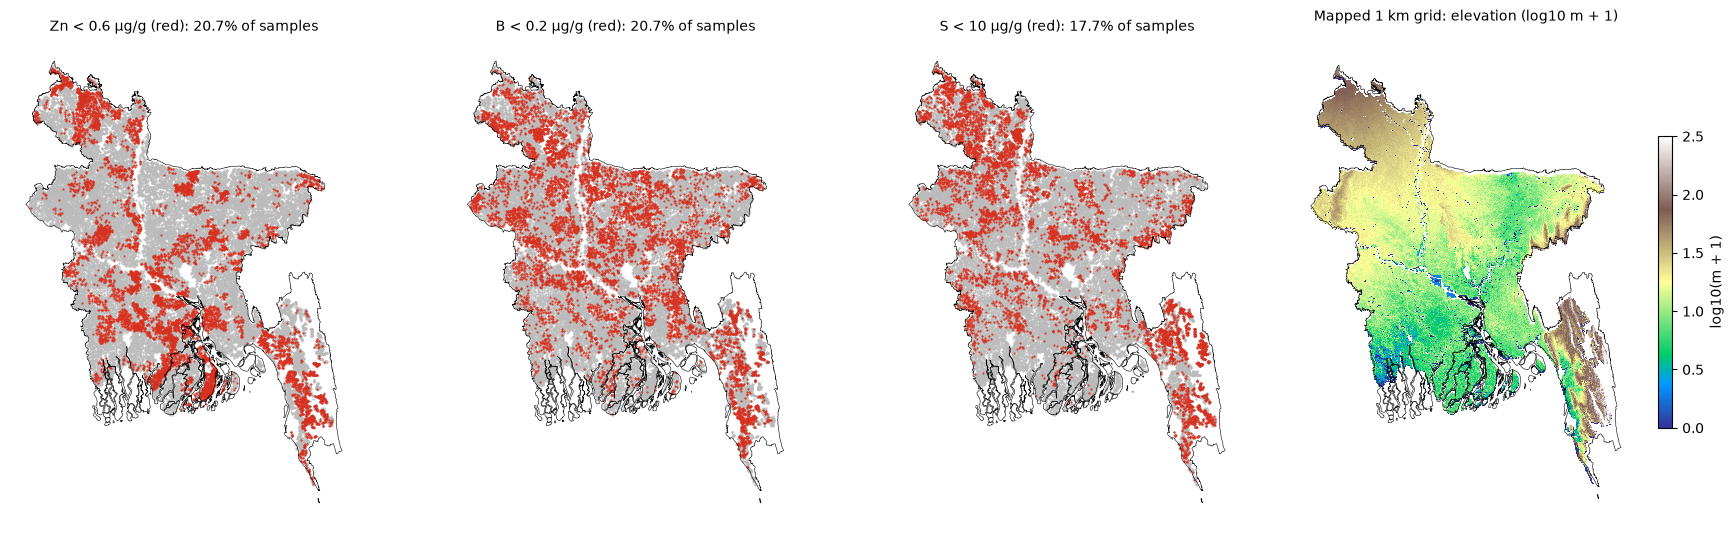

In [5]:
# National outline, and a scatter of grid values in BUTM metres
def base_map(ax, title):
    boundary.boundary.plot(ax=ax, color="k", linewidth=0.4)
    ax.set_title(title, fontsize=10); ax.set_axis_off(); ax.set_aspect("equal")

def grid_map(ax, values, title, cmap="YlOrRd", vmin=0, vmax=1, label="probability", frame=None):
    frame = GM if frame is None else frame
    sc = ax.scatter(frame["X"] * 1000, frame["Y"] * 1000, c=values, s=0.6, marker="s", cmap=cmap, vmin=vmin, vmax=vmax, linewidths=0)
    plt.colorbar(sc, ax=ax, shrink=0.6, label=label)
    base_map(ax, title)

# Deficient samples in red, and elevation on the nodes that will be mapped
fig, axes = plt.subplots(1, 4, figsize=(18, 5.5))
for ax, v in zip(axes[:3], CL):
    lo = soil[f"def_{v}"] == 1
    ax.scatter(soil.loc[~lo, "X"] * 1000, soil.loc[~lo, "Y"] * 1000, s=0.3, c="#bbbbbb")
    ax.scatter(soil.loc[lo, "X"] * 1000, soil.loc[lo, "Y"] * 1000, s=0.3, c="#d7301f")
    base_map(ax, f"{NAME[v]} < {CL[v]:g} µg/g (red): {100 * soil[f'def_{v}'].mean():.1f}% of samples")
grid_map(axes[3], np.log10(1 + GM["ELEV"].clip(lower=0)), "Mapped 1 km grid: elevation (log10 m + 1)",
         cmap="terrain", vmin=0, vmax=2.5, label="log10(m + 1)")
plt.tight_layout(); plt.show()

**Reading the results.**

- **Coordinates recovered.** With the reconstructed system, the projected sample coordinates fall within 10 m of the BUTM position of their longitude and latitude (median 2.6 m), so the samples and the 500 m grid can be placed on the BUTM boundary without loss.
- **Dense sampling.** 37,922 samples cover 6 divisions, 64 districts and 457 upazilas, a median of 71 samples per upazila (2 to 297). Half of the samples have another sample within 1 km, so most of the country is mapped by interpolation over short distances.
- **Gaps.** The white areas are the main rivers, the haor basins, the Sundarbans and parts of the Chittagong Hill Tracts. 98.6% of the 1 km grid lies within 5 km of a sample and is mapped.
- **Ties at the critical level.** 14.8% of B values and 5.8% of Zn values are exactly at the critical level. They are not deficient, but a small change in the level, or in rounding, would move many of them across it.
- **The red points already show clusters** that look like whole upazilas: dense red patches next to grey ones. Section 3 tests this.

## How common is deficiency, and where?

The shares of deficient samples are first shown overall and by the two most useful landscape attributes, the agro-ecological zone (AEZ) and the land type (flooding depth). Soil pH and organic matter control micronutrient availability: Zn availability falls as pH rises, and B and S are leached from light, acid soils. Co-occurrence is measured by the odds ratio between pairs of deficiencies.

,% of samples
Zn < 0.6,20.7
B < 0.2,20.7
S < 10,17.7
S < 14 (FRG 2018),30.7
Cu < 0.2,0.7
Fe < 4.0,0.7
"at least one of Zn, B, S",47.7
all three,0.8


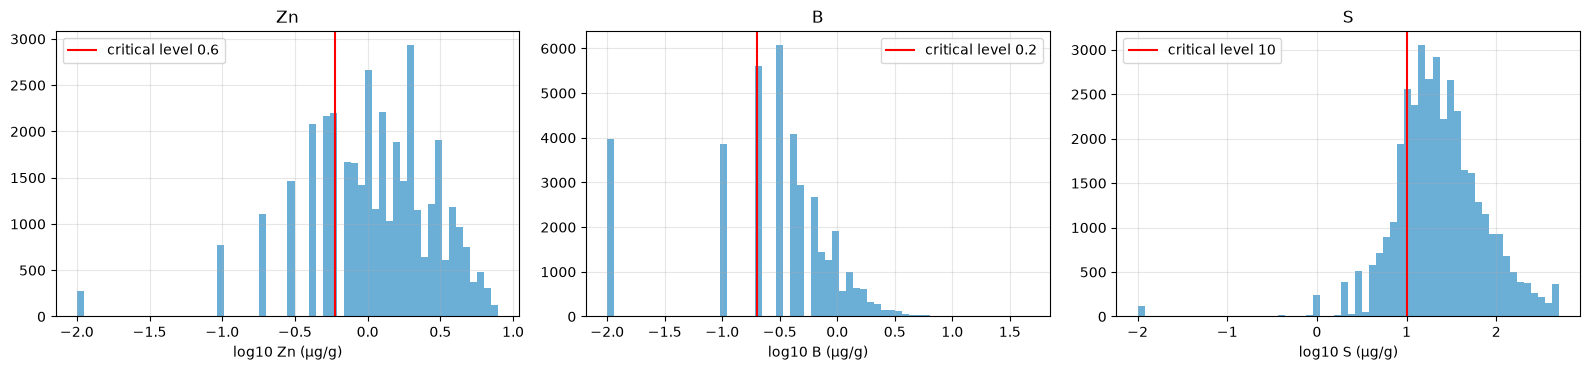

In [6]:
# Share of samples below each critical level, including the FRG 2018 sulfur level of 14 µg/g
share = pd.Series({f"{NAME[v]} < {c:g}": 100 * soil[f"def_{v}"].mean() for v, c in CL.items()})
share["S < 14 (FRG 2018)"] = 100 * (soil["S"] < 14).mean()
share["Cu < 0.2"] = 100 * (soil["CU"] < 0.2).mean()
share["Fe < 4.0"] = 100 * (soil["FE"] < 4.0).mean()
share["at least one of Zn, B, S"] = 100 * soil["def_ANY"].mean()
share["all three"] = 100 * (soil["n_def"] == 3).mean()
display(share.round(1).to_frame("% of samples"))

# Log concentrations, with the critical level marked
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, v in zip(axes, CL):
    # Floor at 0.01 µg/g so a reported zero can be shown on the log scale
    z = soil[v].clip(lower=0.01)
    ax.hist(np.log10(z), bins=60, color="#6baed6")
    ax.axvline(np.log10(CL[v]), color="red", lw=1.5, label=f"critical level {CL[v]:g}")
    ax.set_xlabel(f"log10 {NAME[v]} (µg/g)"); ax.set_title(NAME[v]); ax.legend()
plt.tight_layout(); plt.show()

In [7]:
# Deficiency by zone and land type. Groups with fewer than 100 samples are left out.
def rates_by(col, min_n=100):
    t = soil.groupby(col).agg(n=("def_ZN", "size"), **{f"{NAME[v]} %": (f"def_{v}", "mean") for v in CL},
                              **{"any %": ("def_ANY", "mean"), "pH": ("PH", "median"), "SOM %": ("SOM", "median")})
    for c in t.columns:
        if c.endswith("%") and c != "SOM %":
            t[c] = 100 * t[c]
    return t[t["n"] >= min_n].sort_values("any %", ascending=False)

display(rates_by("AEZ").round(1))
display(rates_by("LT").round(1))

,n,Zn %,B %,S %,any %,pH,SOM %
AEZ,,,,,,,
North-Eastern Barind Tract,351,10.0,52.1,44.4,73.2,5.6,1.1
Lower Meghna River Floodplain,255,57.3,29.0,17.3,71.8,6.1,2.1
Old Himalayan Piedmont Plain,985,25.9,32.4,36.9,68.2,5.2,1.6
Northern and Eastern Hills,4181,23.4,22.1,37.4,64.1,5.2,2.2
Active Ganges Floodplain,492,32.7,30.9,12.4,63.8,7.6,1.8
Chittagong Coastal Plain,926,36.7,23.4,18.5,61.1,5.2,2.0
Tista Meander Floodplain,3479,25.4,21.6,29.4,56.9,5.5,1.5
Low Ganges River Floodplain,2700,37.1,18.7,11.9,55.1,7.5,2.1
Old Brahmaputra Floodplain,2229,17.9,30.5,14.5,50.3,5.4,1.8


,n,Zn %,B %,S %,any %,pH,SOM %
LT,,,,,,,
Highland,12281,20.2,22.7,26.1,54.1,5.4,1.8
Medium Highland 1,3195,23.6,19.9,17.3,48.6,5.7,1.7
Medium Highland 2,12169,22.9,20.2,16.2,47.8,5.9,1.8
Medium Lowland,5876,21.0,21.8,11.4,45.3,5.9,2.1
Lowland,3818,14.2,15.2,8.0,32.6,5.4,2.2
Very Lowland,583,10.5,20.1,3.3,31.6,5.4,2.5


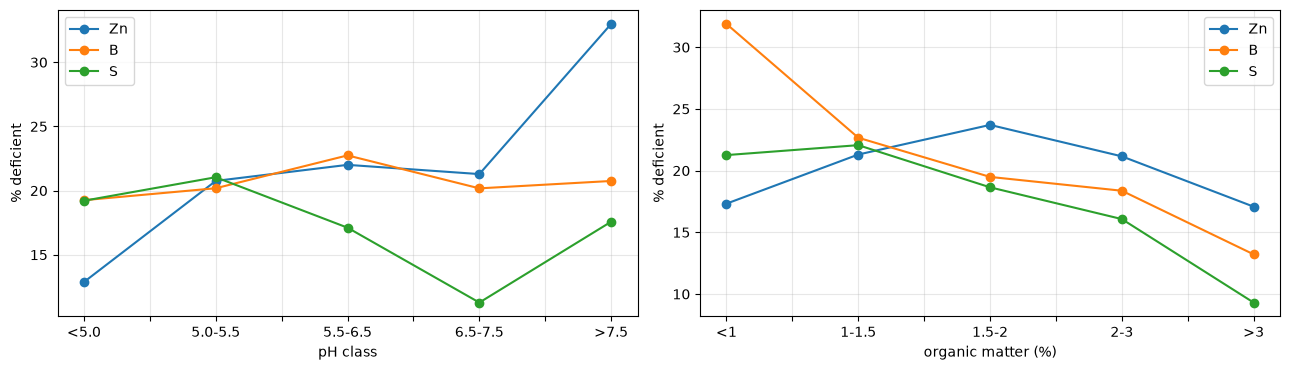

Odds ratios of co-deficiency: {'Zn-B': np.float64(0.64), 'Zn-S': np.float64(1.11), 'B-S': np.float64(1.74)}
Share with at least one deficiency: observed 47.7%, if the three were independent 48.3%


In [8]:
# How deficiency changes with soil pH and organic matter
ph_cls = pd.cut(soil["PH"], [0, 5.0, 5.5, 6.5, 7.5, 14], labels=["<5.0", "5.0-5.5", "5.5-6.5", "6.5-7.5", ">7.5"])
som_cls = pd.cut(soil["SOM"], [0, 1, 1.5, 2, 3, 100], labels=["<1", "1-1.5", "1.5-2", "2-3", ">3"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, cls, lab in [(axes[0], ph_cls, "pH class"), (axes[1], som_cls, "organic matter (%)")]:
    t = soil.groupby(cls)[[f"def_{v}" for v in CL]].mean() * 100
    t.columns = [NAME[v] for v in CL]
    t.plot(ax=ax, marker="o"); ax.set_xlabel(lab); ax.set_ylabel("% deficient")
plt.tight_layout(); plt.show()

# Co-deficiency. Adding half a count to each cell keeps a zero from sending the ratio to infinity.
def odds_ratio(a, b):
    t = pd.crosstab(a, b).to_numpy() + 0.5
    return t[1, 1] * t[0, 0] / (t[1, 0] * t[0, 1])
pairs = [("ZN", "B"), ("ZN", "S"), ("B", "S")]
print("Odds ratios of co-deficiency:", {f"{NAME[a]}-{NAME[b]}": round(odds_ratio(soil[f"def_{a}"], soil[f"def_{b}"]), 2) for a, b in pairs})
# Share with at least one deficiency if Zn, B, and S were independent
expected_any = 1 - np.prod([1 - soil[f"def_{v}"].mean() for v in CL])
print(f"Share with at least one deficiency: observed {100 * soil['def_ANY'].mean():.1f}%, "
      f"if the three were independent {100 * expected_any:.1f}%")

**Reading the results.**

- **One soil in five is deficient in each nutrient.** 20.7% of samples are deficient in Zn, 20.7% in B and 17.7% in S. With the FRG 2018 level of 14 µg/g, S deficiency rises to 30.7%. Cu and Fe deficiencies are rare (0.7% each) and are not mapped.
- **Almost half the soils lack at least one.** 47.7% of samples are deficient in Zn, B or S, but only 0.8% in all three.
- **Agro-ecological zones.** Zn deficiency is highest in the Lower Meghna River Floodplain (57%), the Young Meghna Estuarine Floodplain (42%), the Low Ganges River Floodplain (37%), the Chittagong Coastal Plain (37%) and the Active Ganges Floodplain (33%), and lowest in the High Barind Tract (1%). B deficiency is highest in the North-Eastern Barind Tract (52%) and the Old Himalayan Piedmont Plain (32%).
- **Land type.** S deficiency falls from 26% on highland to 3% on very lowland, consistent with S being lost from aerated soils and conserved under flooding.
- **pH and organic matter.** Zn deficiency rises from 13% at pH below 5 to 33% above pH 7.5, the calcareous Ganges soils. B and S deficiency fall as organic matter rises (B from 32% below 1% organic matter to 13% above 3%).
- **The deficiencies are nearly independent.** Zn and B deficiency are less likely together than apart (odds ratio 0.64), B and S more likely (1.74). Overall, the share with at least one deficiency (47.7%) is close to what independence would give (48.3%).

## Spatial structure and the upazila effect

### Indicator variograms

The indicator semivariogram at the critical level measures how quickly two samples stop sharing their deficiency status as they move apart. With 37,900 samples, all pairs within 30 km are used (about 9 million pairs). `fit_indicator_variogram` from the package computes the same estimator from a random subset of 6,000 samples, as a check. An exponential model with a nugget, γ(h) = c₀ + c₁(1 − exp(−h/a)), is fitted by weighted least squares (weights N(h)/h²). Its practical range is 3a.

,share deficient,p(1-p),nugget,partial sill,a (km),practical range (km),nugget share
target,,,,,,,
Zn,0.207,0.164,0.085,0.070,10.038,30.114,0.548
B,0.207,0.164,0.091,0.077,9.406,28.219,0.542
S,0.177,0.146,0.103,0.037,10.465,31.394,0.736
"Zn, B or S",0.477,0.249,0.158,0.082,8.853,26.559,0.658


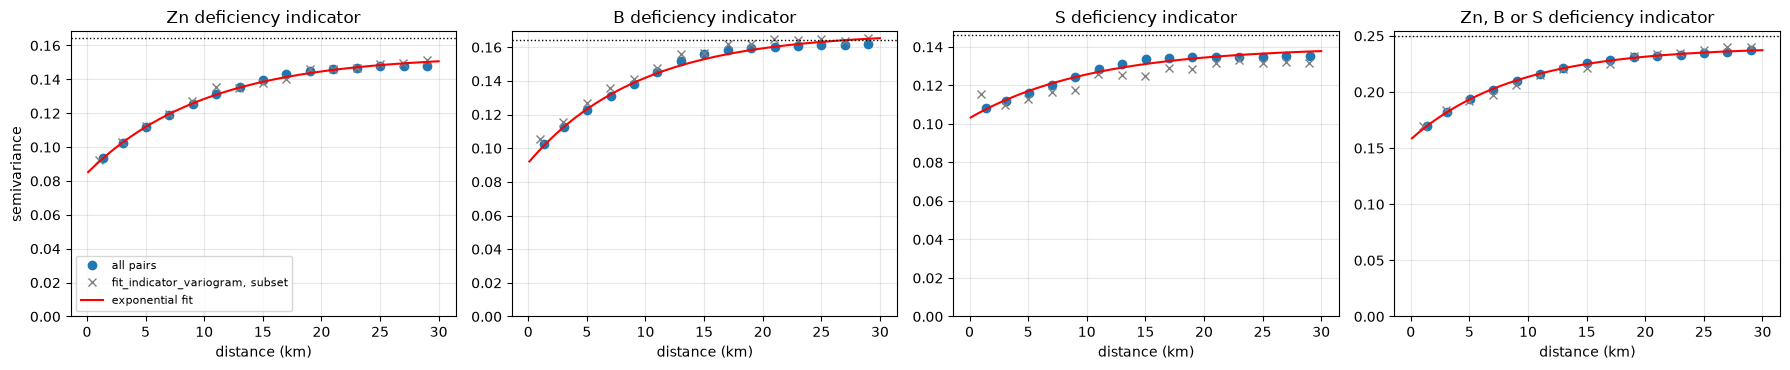

In [9]:
def pair_variogram(xy, z, maxlag=30.0, n_lags=15, groups=None, same=None):
    # Semivariogram from all pairs closer than maxlag (KD tree). same=True keeps pairs in the same group,
    # same=False keeps pairs in different groups.
    pr = cKDTree(xy).query_pairs(maxlag, output_type="ndarray")
    if groups is not None and same is not None:
        k = groups[pr[:, 0]] == groups[pr[:, 1]]
        pr = pr[k if same else ~k]
    d = np.hypot(*(xy[pr[:, 0]] - xy[pr[:, 1]]).T)
    g = 0.5 * (z[pr[:, 0]] - z[pr[:, 1]]) ** 2
    b = np.minimum((d / (maxlag / n_lags)).astype(int), n_lags - 1)
    n = np.bincount(b, minlength=n_lags)
    return np.bincount(b, d, n_lags) / n, np.bincount(b, g, n_lags) / n, n

# Exponential model with a nugget, fitted by weighted least squares
def fit_exp(h, g, n):
    # Sill guess from the last three lags: 40% nugget, 60% partial sill, range 10 km
    v = np.nanmean(g[-3:])
    # Scale the residual by sqrt(n) / h, with h at least 0.5 km, so squared error has weight n/h^2
    f = lambda p: np.sqrt(n / np.maximum(h, 0.5) ** 2) * (p[0] + p[1] * (1 - np.exp(-h / p[2])) - g)
    r = least_squares(f, [0.4 * v, 0.6 * v, 10.0], bounds=([0, 1e-6, 0.5], [np.inf, np.inf, 1000]))
    return tuple(float(x) for x in r.x)          # (nugget, partial sill, a in km)

def exp_gamma(h, p):
    return p[0] + p[1] * (1 - np.exp(-np.asarray(h) / p[2]))

# Deficiency indicators for Zn, B, S, and for any of the three
TARGETS = list(CL) + ["ANY"]
IND = {t: soil[f"def_{t}"].to_numpy().astype(float) for t in TARGETS}
VG, VP = {}, {}
rs = np.random.default_rng(SEED)
sub = rs.choice(len(soil), 6000, replace=False)
rows = []
for t in TARGETS:
    VG[t] = pair_variogram(XY, IND[t])
    VP[t] = fit_exp(*VG[t])
    p = IND[t].mean()
    rows.append({"target": NAME[t], "share deficient": p, "p(1-p)": p * (1 - p), "nugget": VP[t][0],
                 "partial sill": VP[t][1], "a (km)": VP[t][2], "practical range (km)": 3 * VP[t][2],
                 "nugget share": VP[t][0] / (VP[t][0] + VP[t][1])})
display(pd.DataFrame(rows).set_index("target").round(3))

# Fitted curves against the empirical lags. The dotted line is the indicator variance p(1-p).
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
hh = np.linspace(0.1, 30, 200)
for ax, t in zip(axes, TARGETS):
    h, g, n = VG[t]
    ax.plot(h, g, "o", label="all pairs")
    # package estimator on a 6,000-sample subset (indicator I(z < c) coded via the deficiency flag)
    lags, gam = fit_indicator_variogram(XY[sub], IND[t][sub], threshold=0.5, maxlag=30, n_lags=15)
    ax.plot(lags, gam, "x", color="grey", label="fit_indicator_variogram, subset")
    ax.plot(hh, exp_gamma(hh, VP[t]), "r-", label="exponential fit")
    ax.axhline(IND[t].mean() * (1 - IND[t].mean()), color="k", ls=":", lw=1)
    ax.set_ylim(0, None); ax.set_xlabel("distance (km)"); ax.set_title(f"{NAME[t]} deficiency indicator")
axes[0].set_ylabel("semivariance"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Do upazila boundaries matter?

The samples were collected and analysed upazila by upazila. If each upazila survey differed in its year, laboratory or sampling practice, two samples 1 km apart would differ more when a boundary separates them than when they lie in the same upazila. Real soil properties do not jump at administrative boundaries, so a jump points to the survey. The test compares the semivariance of pairs at the same distance within and across upazilas, for the deficiency indicators and for the log nutrient values, and reports the share of the variance that lies between upazila means.

Pairs 0-2 km apart: 87,364 within upazilas, 7,015 across a boundary


,within 0-2 km,within 2-4 km,within 4-6 km,across 0-2 km,across 2-4 km,across 4-6 km,across/within 0-2 km,between-upazila share of variance
variable,,,,,,,,
Zn indicator,0.090,0.092,0.096,0.144,0.146,0.146,1.611,0.478
log Zn,0.256,0.277,0.297,0.740,0.753,0.762,2.891,0.669
B indicator,0.097,0.101,0.104,0.163,0.160,0.161,1.675,0.317
log B,0.487,0.518,0.546,0.909,0.914,0.914,1.865,0.426
S indicator,0.106,0.107,0.109,0.132,0.131,0.131,1.249,0.290
log S,0.509,0.550,0.579,0.878,0.846,0.844,1.726,0.520


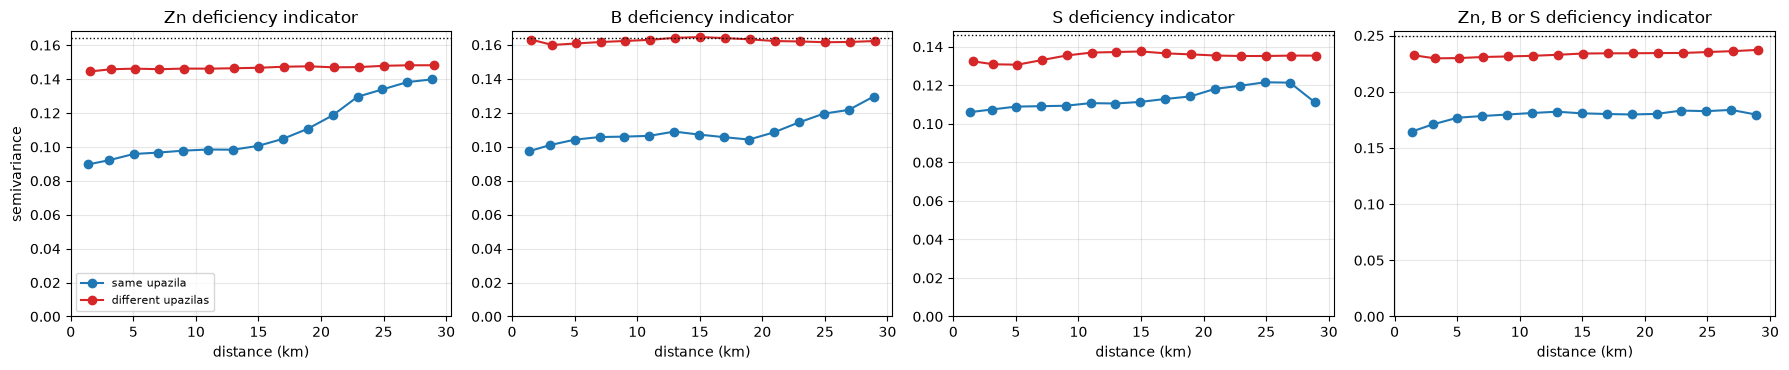

Within-upazila variogram fits (nugget, partial sill, a km): {'Zn': (0.088, 0.122, 104.193), 'B': (0.093, 0.015, 3.743), 'S': (0.105, 0.011, 14.501), 'Zn, B or S': (0.156, 0.026, 3.376)}


In [10]:
# Short-lag semivariance for pairs inside an upazila and pairs across its boundary
rows = []
for v in CL:
    # Floor at 0.05 µg/g so a reported zero, which for boron means below that step, can enter the log
    zl = np.log(soil[v].clip(lower=0.05).to_numpy())
    for lab, z in [(f"{NAME[v]} indicator", IND[v]), (f"log {NAME[v]}", zl)]:
        hw, gw, nw = pair_variogram(XY, z, maxlag=6, n_lags=3, groups=UPZ, same=True)
        ha, ga, na = pair_variogram(XY, z, maxlag=6, n_lags=3, groups=UPZ, same=False)
        up_mean = pd.Series(z).groupby(UPZ).transform("mean")
        rows.append({"variable": lab,
                     **{f"within {a}-{b} km": gw[i] for i, (a, b) in enumerate([(0, 2), (2, 4), (4, 6)])},
                     **{f"across {a}-{b} km": ga[i] for i, (a, b) in enumerate([(0, 2), (2, 4), (4, 6)])},
                     "across/within 0-2 km": ga[0] / gw[0],
                     "between-upazila share of variance": up_mean.var() / z.var()})
print(f"Pairs 0-2 km apart: {int(nw[0]):,} within upazilas, {int(na[0]):,} across a boundary")
boundary_tab = pd.DataFrame(rows).set_index("variable")
display(boundary_tab.round(3))

# Full curves within and across upazilas, and an exponential fit that uses within-upazila pairs only
VP_IN = {t: fit_exp(*pair_variogram(XY, IND[t], groups=UPZ, same=True)) for t in TARGETS}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, t in zip(axes, TARGETS):
    for same, lab, c in [(True, "same upazila", "C0"), (False, "different upazilas", "C3")]:
        h, g, n = pair_variogram(XY, IND[t], groups=UPZ, same=same)
        ok = n > 200
        ax.plot(h[ok], g[ok], "o-", color=c, label=lab)
    ax.axhline(IND[t].mean() * (1 - IND[t].mean()), color="k", ls=":", lw=1)
    ax.set_ylim(0, None); ax.set_xlabel("distance (km)"); ax.set_title(f"{NAME[t]} deficiency indicator")
axes[0].set_ylabel("semivariance"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Within-upazila variogram fits (nugget, partial sill, a km):", {NAME[t]: tuple(round(x, 3) for x in VP_IN[t]) for t in TARGETS})

**Reading the results.**

- **Short ranges and large nuggets.** The indicator variograms reach their sill within a practical range of 28 to 31 km. The nugget is 54% of the sill for Zn and B and 74% for S, so even neighbouring samples often differ in deficiency status.
- **A jump at upazila boundaries.** At 0 to 2 km, pairs on opposite sides of an upazila boundary are 1.6 times as dissimilar as pairs in the same upazila for the Zn indicator, 1.7 times for B and 1.25 times for S. For the log values the ratio is 2.9 (Zn), 1.9 (B) and 1.7 (S). Pairs across a boundary are almost at the sill even 1 km apart, while pairs within an upazila stay well below it over 10 to 20 km.
- **Upazila means hold much of the variance.** 48% of the variance of the Zn indicator, and 67% of the variance of log Zn, lies between upazila means. For B the shares are 32% and 43%, for S 29% and 52%.
- **Within an upazila there is little spatial structure.** The within-upazila variograms of B and S are almost flat: once the upazila is known, the distance to the next sample adds little.

Soil properties change gradually, not at administrative boundaries, so most of this jump is a survey effect: each upazila was probably sampled in a different year, by a different team or analysed in a different batch. It might also include real differences, where an upazila boundary follows a river or a terrace edge. For mapping, the consequence is the same: samples from the same upazila are far better neighbours than samples across the boundary.

## Comparing estimators

Five estimators of the probability of deficiency are compared:

| Estimator | Idea |
|---|---|
| **Upazila mean** | The share of deficient samples in the upazila. The baseline that Section 3 suggests. |
| **IK** | Ordinary indicator kriging with the 32 nearest samples (`IndicatorKriging`, exponential model of Section 3.1). |
| **IK within upazila** | Indicator kriging using only samples of the same upazila, with the within-upazila variogram. Where the upazila has no training samples, it falls back to IK. |
| **RF** | A random forest classifier on the landscape attributes (AEZ, cropping pattern, geology as dummies; land type, drainage class and elevation) and the coordinates. |
| **RF + SK** | A random forest on the landscape attributes only, with its out-of-bag residuals kriged by simple kriging and added back. This is regression kriging for an indicator. |

`IndicatorKriging` returns P(Z ≥ t), so the probability of deficiency is 1 − P(Z ≥ c).

Validation uses six schemes, from easiest to hardest: random 5-fold cross-validation; spatial blocks of 2, 5, 10 and 25 km assigned to 5 folds; and whole districts held out (5 folds of about 13 districts). Larger blocks force predictions farther from the nearest training sample, so the schemes show how skill decays with distance. The scores are the Brier score (lower is better), the Brier skill score against the national share (BSS, higher is better, 0 means no skill) and the area under the ROC curve (AUC).

In [11]:
def p_deficient_ik(xy_tr, z_tr, xy_te, params, k=K):
    # P(Z < c) from IndicatorKriging, which returns P(I >= t). The deficiency indicator is kriged directly:
    # threshold 0.5 on the 0/1 indicator, so P(indicator >= 0.5) = P(deficient).
    ik = IndicatorKriging(cov_model="exponential", max_neighbors=min(k, len(z_tr)), use_gpu=USE_GPU).fit(xy_tr, z_tr)
    return np.clip(ik.predict(xy_te, [0.5], {0.5: params})[0.5], 0, 1)

# Krige inside the upazila, and fall back to the national model where the upazila is too small
def p_deficient_ik_upazila(xy_tr, z_tr, g_tr, xy_te, g_te, params_in, params_all, k=K):
    out = np.full(len(xy_te), np.nan)
    for g in np.unique(g_te):
        it, ip = np.flatnonzero(g_tr == g), np.flatnonzero(g_te == g)
        # Local kriging needs at least five samples and both classes
        if len(it) >= 5 and z_tr[it].min() != z_tr[it].max():
            out[ip] = p_deficient_ik(xy_tr[it], z_tr[it], xy_te[ip], params_in, k)
        # Every training sample in the upazila carries the same label, so the probability is that label
        elif len(it) >= 5:
            out[ip] = z_tr[it][0]
    # Nodes still empty take indicator kriging on all training samples
    miss = np.isnan(out)
    if miss.any():
        out[miss] = p_deficient_ik(xy_tr, z_tr, xy_te[miss], params_all, k)
    return out

def simple_krige_local(xy, r, xp, params, k=K, chunk=4000):
    # Local simple kriging (mean 0) of residuals with an exponential covariance.
    nug, ps, a = params
    tree = cKDTree(xy); out = np.empty(len(xp))
    cov = lambda d: ps * np.exp(-d / a) + nug * (d < 1e-9)
    # Predict in chunks so the neighbour-distance matrices stay small
    for c0 in range(0, len(xp), chunk):
        p = xp[c0:c0 + chunk]
        dd, ii = tree.query(p, k=k)
        nb = xy[ii]
        D = np.sqrt(((nb[:, :, None, :] - nb[:, None, :, :]) ** 2).sum(-1))
        w = np.linalg.solve(cov(D), cov(dd)[:, :, None])[:, :, 0]
        out[c0:c0 + len(p)] = (w * r[ii]).sum(1)
    return out

# Dummies for zone, cropping pattern, and geology, plus land type, drainage, and elevation
def landscape_features(df, coords):
    F = pd.get_dummies(df[["AEZ_ID", "CP_ID", "SGEO_ID"]].astype("category"), dtype=float)
    cols = ["LT_ID", "DC_ID", "ELEV"] + (["X", "Y"] if coords else [])
    F[cols] = df[cols].to_numpy(float)
    return F

# Shared dummy columns for samples and grid
_all = pd.concat([soil[["AEZ_ID", "CP_ID", "SGEO_ID", "LT_ID", "DC_ID", "ELEV", "X", "Y"]],
                  GM[["AEZ_ID", "CP_ID", "SGEO_ID", "LT_ID", "DC_ID", "ELEV", "X", "Y"]]], ignore_index=True)
F_XY_ALL, F_NO_ALL = landscape_features(_all, True).to_numpy(), landscape_features(_all, False).to_numpy()
F_XY, F_NO = F_XY_ALL[:len(soil)], F_NO_ALL[:len(soil)]
G_XY, G_NO = F_XY_ALL[len(soil):], F_NO_ALL[len(soil):]
# Each tree sees 30% of the features and half the rows, and each leaf holds at least five samples
RF_KW = dict(n_estimators=N_TREES, min_samples_leaf=5, max_features=0.3, max_samples=0.5, n_jobs=-1, random_state=SEED)
print("Landscape features:", F_NO.shape[1], "(plus X, Y for RF)")

Landscape features: 92 (plus X, Y for RF)


In [12]:
# Spatial block ids. Multiplying the x block by 100000 keeps it from colliding with the y block.
def blocks(km):
    return (np.floor(XY[:, 0] / km) * 100000 + np.floor(XY[:, 1] / km)).astype(np.int64)

# Random 5-fold, then spatial blocks from 2 km to 25 km, then whole districts
SCHEMES = [("random", KFold(5, shuffle=True, random_state=SEED), None)]
SCHEMES += [(f"{b} km blocks", GroupKFold(5), blocks(b)) for b in (2, 5, 10, 25)]
SCHEMES += [("districts", GroupKFold(5), soil["DIST_NAME"].fillna("NA").to_numpy())]
METHODS = ["Upazila mean", "IK", "IK within upazila", "RF", "RF + SK"]

def predict_all(tr, te, t, xp=None, gp=None, Fxy_p=None, Fno_p=None):
    # Fit every estimator on samples `tr` and predict at the test samples `te` (or at new points xp).
    z = IND[t]
    xp = XY[te] if xp is None else xp
    gp = UPZ[te] if gp is None else gp
    Fxy_p = F_XY[te] if Fxy_p is None else Fxy_p
    Fno_p = F_NO[te] if Fno_p is None else Fno_p
    out = {}
    # Upazila rate, or the training prevalence where that upazila is missing from the fold
    mu = pd.Series(z[tr]).groupby(UPZ[tr]).mean()
    out["Upazila mean"] = pd.Series(gp).map(mu).fillna(z[tr].mean()).to_numpy()
    out["IK"] = p_deficient_ik(XY[tr], z[tr], xp, VP[t])
    out["IK within upazila"] = p_deficient_ik_upazila(XY[tr], z[tr], UPZ[tr], xp, gp, VP_IN[t], VP[t])
    # Forest on landscape attributes and coordinates
    rf = RandomForestClassifier(**RF_KW).fit(F_XY[tr], z[tr])
    out["RF"] = rf.predict_proba(Fxy_p)[:, 1]
    # Forest on landscape attributes alone. Simple kriging adds its out-of-bag residuals.
    rf2 = RandomForestClassifier(oob_score=True, **RF_KW).fit(F_NO[tr], z[tr])
    resid = z[tr] - rf2.oob_decision_function_[:, 1]
    vp_r = fit_exp(*pair_variogram(XY[tr], resid))
    out["RF + SK"] = np.clip(rf2.predict_proba(Fno_p)[:, 1] + simple_krige_local(XY[tr], resid, xp, vp_r), 0, 1)
    return out

# Brier score, skill against the national share, and AUC for every blocking scheme
t0 = time.time()
CVP = {}
cv_rows = []
for t in TARGETS:
    z = IND[t]
    base = brier_score_loss(z, np.full(len(z), z.mean()))
    for sname, splitter, groups in SCHEMES:
        P = {m: np.zeros(len(z)) for m in METHODS}
        for tr, te in splitter.split(XY, z, groups):
            for m, p in predict_all(tr, te, t).items():
                P[m][te] = p
        CVP[(t, sname)] = P
        for m in METHODS:
            bs = brier_score_loss(z, P[m])
            cv_rows.append({"target": NAME[t], "scheme": sname, "method": m, "Brier": bs,
                            "BSS": 1 - bs / base, "AUC": roc_auc_score(z, P[m])})
    print(f"{NAME[t]}: done after {time.time() - t0:.0f} s", flush=True)
CV = pd.DataFrame(cv_rows)

Zn: done after 74 s


B: done after 154 s


S: done after 229 s


Zn, B or S: done after 307 s


In [13]:
# Brier skill against the national share, and AUC, for every target and scheme
scheme_order = [s for s, _, _ in SCHEMES]
bss = CV.pivot_table(index=["target", "method"], columns="scheme", values="BSS")[scheme_order]
auc = CV.pivot_table(index=["target", "method"], columns="scheme", values="AUC")[scheme_order]
order = pd.MultiIndex.from_product([[NAME[t] for t in TARGETS], METHODS])
print("Brier skill score (0 = no better than the national share)")
display(bss.reindex(order).round(3))
print("AUC")
display(auc.reindex(order).round(3))

Brier skill score (0 = no better than the national share)


scheme                        random  2 km blocks  5 km blocks  10 km blocks  25 km blocks  districts
Zn         Upazila mean        0.466        0.464        0.453         0.445         0.330     -0.006
           IK                  0.449        0.436        0.396         0.339         0.184     -0.250
           IK within upazila   0.496        0.488        0.469         0.447         0.296     -0.250
           RF                  0.362        0.348        0.306         0.259         0.150     -0.066
           RF + SK             0.421        0.404        0.360         0.298         0.176     -0.077
B          Upazila mean        0.297        0.294        0.286         0.266         0.184     -0.008
           IK                  0.275        0.261        0.231         0.191         0.084     -0.251
           IK within upazila   0.320        0.313        0.295         0.273         0.172     -0.251
           RF                  0.202        0.191        0.164         0.124         0.061     -0.074
           RF + SK             0.254        0.241        0.208         0.164         0.082     -0.098
S          Upazila mean        0.270        0.269        0.261         0.242         0.145     -0.010
           IK                  0.266        0.257        0.233         0.197         0.103     -0.135
           IK within upazila   0.293        0.289        0.274         0.247         0.159     -0.135
           RF                  0.210        0.202        0.179         0.151         0.091      0.026
           RF + SK             0.244        0.235        0.210         0.179         0.103      0.001
Zn, B or S Upazila mean        0.286        0.285        0.274         0.263         0.169     -0.003
           IK                  0.280        0.270        0.239         0.205         0.109     -0.156
           IK within upazila   0.312        0.307        0.284         0.267         0.183     -0.156
           RF                  0.229        0.220        0.196         0.166         0.103      0.001
           RF + SK             0.258        0.247        0.217         0.183         0.110     -0.011

AUC


scheme                        random  2 km blocks  5 km blocks  10 km blocks  25 km blocks  districts
Zn         Upazila mean        0.924        0.924        0.920         0.917         0.865      0.432
           IK                  0.914        0.910        0.895         0.871         0.795      0.590
           IK within upazila   0.931        0.929        0.924         0.916         0.855      0.590
           RF                  0.880        0.875        0.855         0.831         0.754      0.620
           RF + SK             0.901        0.895        0.878         0.849         0.772      0.603
B          Upazila mean        0.849        0.847        0.844         0.833         0.787      0.420
           IK                  0.835        0.826        0.811         0.785         0.715      0.528
           IK within upazila   0.858        0.854        0.847         0.834         0.781      0.528
           RF                  0.796        0.787        0.767         0.734         0.676      0.550
           RF + SK             0.822        0.814        0.795         0.765         0.701      0.545
S          Upazila mean        0.852        0.850        0.847         0.837         0.779      0.403
           IK                  0.845        0.840        0.826         0.806         0.740      0.611
           IK within upazila   0.861        0.858        0.852         0.838         0.787      0.611
           RF                  0.815        0.808        0.794         0.775         0.723      0.669
           RF + SK             0.831        0.826        0.812         0.794         0.736      0.655
Zn, B or S Upazila mean        0.809        0.809        0.803         0.798         0.750      0.462
           IK                  0.806        0.801        0.783         0.762         0.705      0.570
           IK within upazila   0.823        0.821        0.809         0.801         0.758      0.570
           RF                  0.778        0.772        0.756         0.734         0.684      0.598
           RF + SK             0.794        0.788        0.770         0.748         0.695      0.600

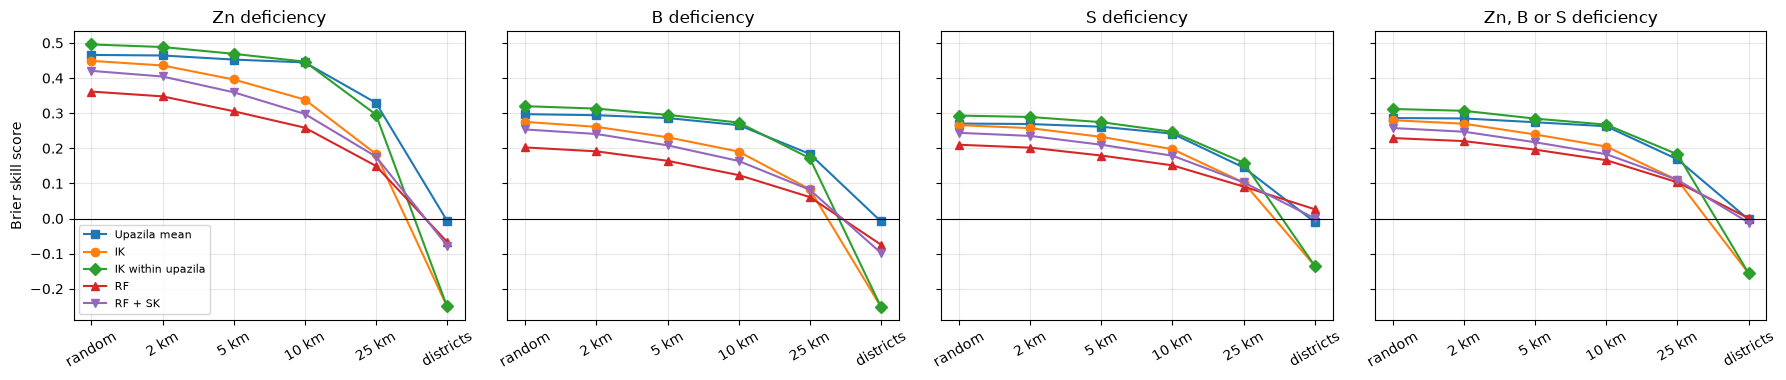

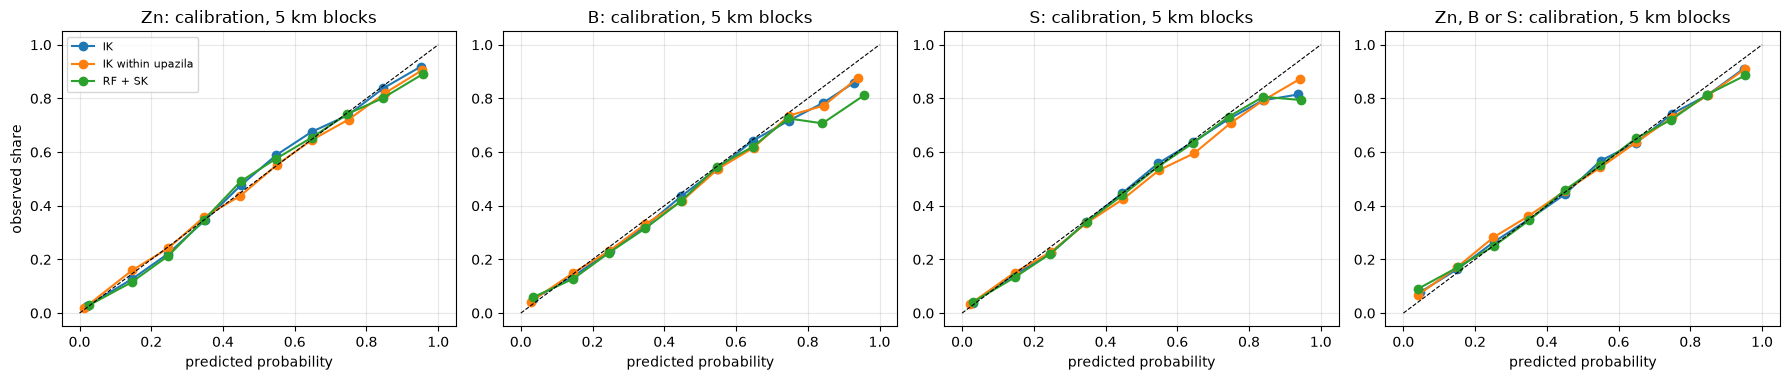

In [14]:
# Skill as the held-out blocks get larger. A score of zero equals the national share.
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9), sharey=True)
xs = np.arange(len(scheme_order))
for ax, t in zip(axes, TARGETS):
    for m, mk in zip(METHODS, ["s", "o", "D", "^", "v"]):
        ax.plot(xs, bss.loc[(NAME[t], m)].to_numpy(), marker=mk, label=m)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(xs); ax.set_xticklabels([s.replace(" blocks", "") for s in scheme_order], rotation=30)
    ax.set_title(f"{NAME[t]} deficiency")
axes[0].set_ylabel("Brier skill score"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Calibration of the 5 km block predictions
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9))
# Ten equal probability bins. The dashed line is perfect calibration.
bins = np.linspace(0, 1, 11)
for ax, t in zip(axes, TARGETS):
    for m in ["IK", "IK within upazila", "RF + SK"]:
        p = CVP[(t, "5 km blocks")][m]
        b = np.digitize(p, bins[1:-1])
        obs = pd.Series(IND[t]).groupby(b).mean(); prd = pd.Series(p).groupby(b).mean()
        ax.plot(prd, obs, "o-", label=m)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("predicted probability"); ax.set_title(f"{NAME[t]}: calibration, 5 km blocks")
axes[0].set_ylabel("observed share"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the results.**

- **IK within upazila is best wherever there are samples nearby.** Its Brier skill score for Zn is 0.50 in random cross-validation and 0.45 with 10 km blocks, with AUC 0.93 and 0.92. For B and S the scores are lower (BSS 0.32 and 0.29 in random CV) but the ranking is the same.
- **The upazila mean is almost as good.** It is within 0.03 BSS of IK within upazila up to 10 km, and better at 25 km for Zn and B. Most of the predictable variation is the upazila level itself.
- **Plain IK loses skill quickly.** It borrows from samples across upazila boundaries, which Section 3 showed are poor neighbours. For Zn its BSS falls from 0.45 to 0.18 between random CV and 25 km blocks.
- **Landscape attributes add little.** The random forest has the lowest skill at every scale up to 25 km (Zn BSS 0.36 in random CV). Kriging its residuals adds about 0.05, but it never reaches the upazila mean. The coordinates are its most important inputs, so it also learns location rather than landscape.
- **No method predicts an unsampled district.** With whole districts held out, every BSS is between −0.25 and 0.03. IK becomes worse than the national share, because it carries the deficiency level of neighbouring districts across the boundary. The maps are therefore only valid inside sampled upazilas.
- **Calibration is good.** In the 5 km block test, the observed share of deficient samples follows the predicted probability closely for all three IK-based estimators.

## Deficiency probability maps

The final maps use all samples. Two estimators are shown for each nutrient: IK, which gives a smooth surface, and IK within upazila, which scored best in Section 4 and respects the survey units. Within-upazila maps change abruptly where the nearest sample switches upazila. Those edges approximate the real upazila boundaries.

Grid predictions: 11 s for 118,000 nodes


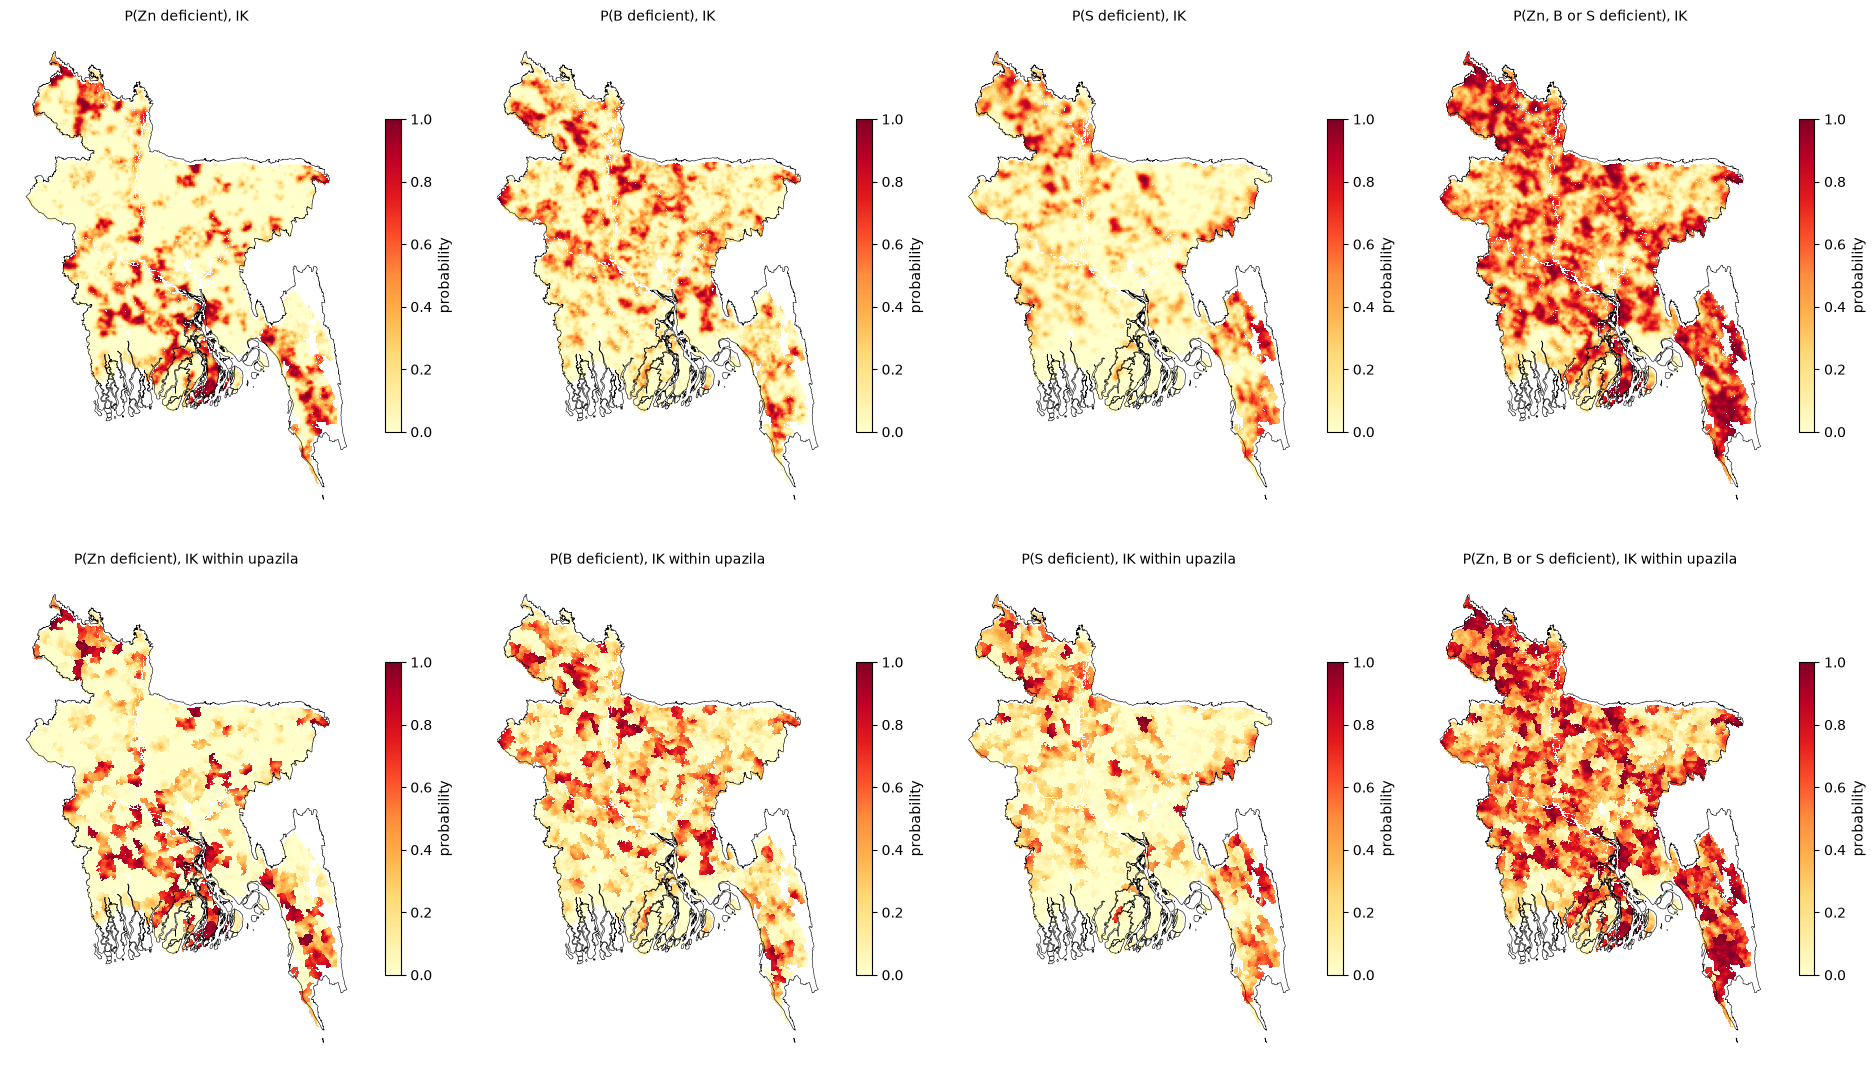

In [15]:
# Indicator kriging at every mapped node, using all samples and again within each upazila
ALL = np.arange(len(soil))
MAPS = {}
t0 = time.time()
for t in TARGETS:
    z = IND[t]
    MAPS[(t, "IK")] = p_deficient_ik(XY, z, GMXY, VP[t])
    MAPS[(t, "IK within upazila")] = p_deficient_ik_upazila(XY, z, UPZ, GMXY, GM["upazila"].to_numpy(), VP_IN[t], VP[t])
print(f"Grid predictions: {time.time() - t0:.0f} s for {len(GM):,} nodes")

# Probability of deficiency for Zn, B, S, and for any of the three
fig, axes = plt.subplots(2, 4, figsize=(19, 11))
for j, t in enumerate(TARGETS):
    for i, m in enumerate(["IK", "IK within upazila"]):
        grid_map(axes[i, j], MAPS[(t, m)], f"P({NAME[t]} deficient), {m}")
plt.tight_layout(); plt.show()

,Zn,B,S
Y,0.309,0.300,0.294
X,0.279,0.289,0.254
geology,0.102,0.068,0.062
elevation,0.096,0.113,0.167
AEZ,0.083,0.087,0.076
cropping pattern,0.082,0.076,0.070
LT_ID,0.028,0.039,0.035
DC_ID,0.020,0.029,0.043


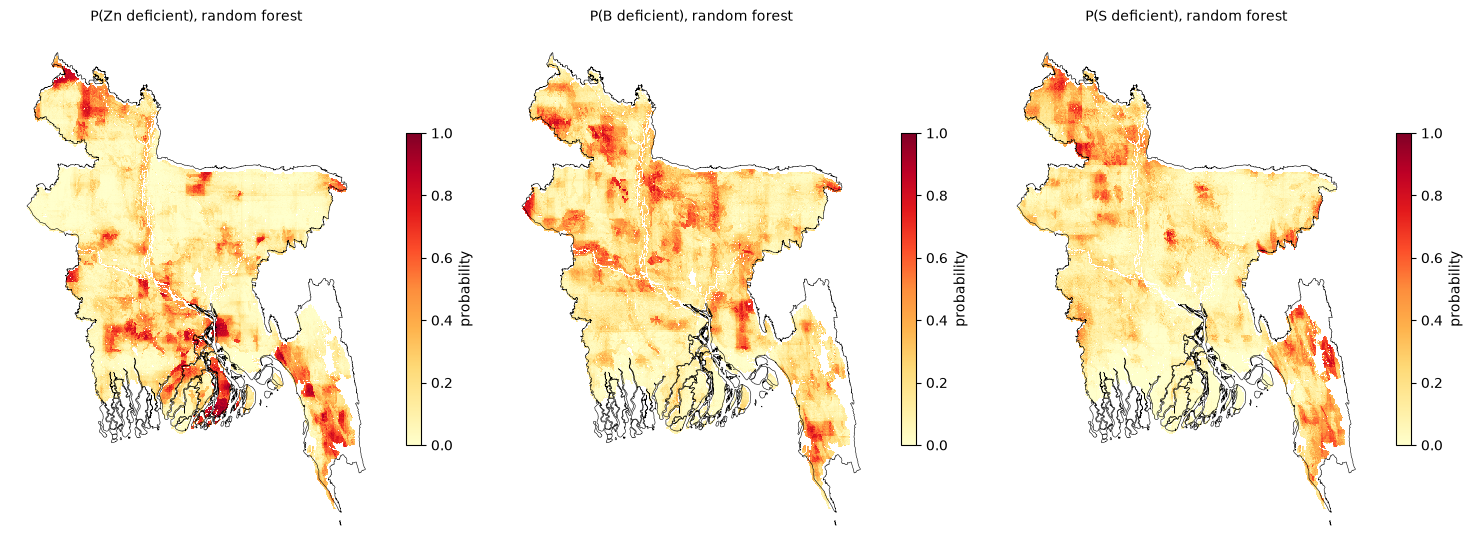

Correlation between the RF and IK-within-upazila maps: {'Zn': np.float64(0.8), 'B': np.float64(0.76), 'S': np.float64(0.78)}


In [16]:
# Random forest map for comparison (all samples), and landscape effects
rf_maps = {}
imp_rows = {}
feat_names = landscape_features(_all, True).columns
for t in CL:
    rf = RandomForestClassifier(**RF_KW).fit(F_XY, IND[t])
    rf_maps[t] = rf.predict_proba(G_XY)[:, 1]
    imp = pd.Series(rf.feature_importances_, index=feat_names)
    # Add the one-hot columns back up to one importance per landscape factor
    grp = imp.groupby(lambda c: c.split("_")[0] if "_ID_" in c else c).sum()
    imp_rows[NAME[t]] = grp
imp_tab = pd.DataFrame(imp_rows).rename(index={"AEZ": "AEZ", "CP": "cropping pattern", "SGEO": "geology",
                                               "LT": "land type", "DC": "drainage", "ELEV": "elevation"})
display(imp_tab.sort_values("Zn", ascending=False).round(3))

# Forest probabilities on the mapping grid, for comparison with within-upazila indicator kriging
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, t in zip(axes, CL):
    grid_map(ax, rf_maps[t], f"P({NAME[t]} deficient), random forest")
plt.tight_layout(); plt.show()
# How closely the forest map agrees with indicator kriging inside upazilas
print("Correlation between the RF and IK-within-upazila maps:",
      {NAME[t]: round(np.corrcoef(rf_maps[t], MAPS[(t, 'IK within upazila')])[0, 1], 2) for t in CL})

**Reading the results.**

- **Two pictures of the same data.** The IK maps show smooth patches 20 to 40 km across. The within-upazila maps break the same pattern into upazila-shaped units, which is closer to how the data were produced and scored better in Section 4.
- **Zn deficiency** is concentrated in the south-central floodplains (Bhola 81% and Jhalokati 79% of samples deficient, Madaripur and Barisal 43% to 47%), Narail (64%), the far north (Nilphamari 59%, Panchagarh 47%) and Bandarban (50%).
- **B deficiency** is most common in Jamalpur (56%), Rangpur (54%), Cox's Bazar (52%) and Sherpur (41%), and in patches along the Brahmaputra-Jamuna and in the northwest.
- **S deficiency** is most likely in the far north (Panchagarh 47%, Dinajpur 37%, Lalmonirhat and Nilphamari 36%) and in the Chittagong Hill Tracts (Rangamati 46%, Khagrachhari 39%, Bandarban 37%).
- **The random forest agrees on the broad pattern** (correlation 0.76 to 0.80 with the within-upazila maps), but its map is blocky. Its most important inputs are the coordinates (55% to 59% of the importance), followed by elevation, geology, AEZ and cropping pattern. The landscape maps are too coarse to separate deficient from non-deficient fields within a zone.

## Several deficiencies at once

Three quantities describe co-deficiency:

- **P(at least one deficient):** the "any" indicator kriged directly. It is not computed from the three separate probabilities, because the deficiencies are correlated (Section 2).
- **Expected number of deficient nutrients:** the sum of the three probabilities. An expectation is additive whether or not the events are independent, so this needs no assumption.
- **Main deficiency:** the nutrient with the highest probability where that probability exceeds 0.5.

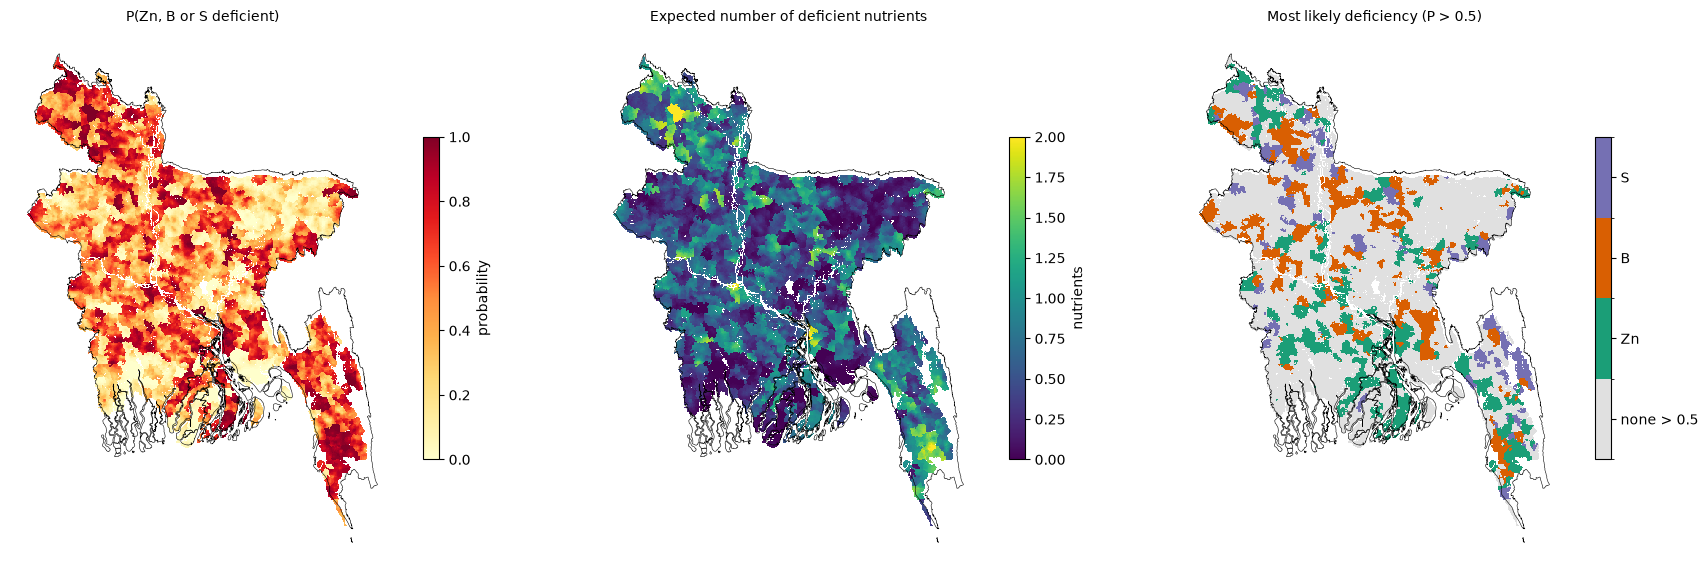

,% of mapped area
P(Zn) > 0.5,17.1
P(B) > 0.5,17.2
P(S) > 0.5,11.2
P(any) > 0.5,46.6
expected number >= 1,18.5
"expected share deficient, Zn",18.7
"expected share deficient, B",22.7
"expected share deficient, S",17.7
"expected share deficient, any",47.3


In [17]:
# Within-upazila probabilities. The any-deficiency map is kriged on its own indicator.
best = "IK within upazila"
P3 = np.column_stack([MAPS[(t, best)] for t in CL])
GM["p_any"] = MAPS[("ANY", best)]
GM["expected_n"] = P3.sum(1)
# Leading nutrient only where its probability exceeds 0.5
main = np.where(P3.max(1) > 0.5, P3.argmax(1) + 1, 0)
GM["main"] = main
for j, t in enumerate(CL):
    GM[f"p_{t}"] = P3[:, j]

# Any-deficiency probability, expected count of deficient nutrients, and the leading nutrient
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
grid_map(axes[0], GM["p_any"], "P(Zn, B or S deficient)")
grid_map(axes[1], GM["expected_n"], "Expected number of deficient nutrients", cmap="viridis", vmin=0, vmax=2, label="nutrients")
cmap = ListedColormap(["#e0e0e0", "#1b9e77", "#d95f02", "#7570b3"])
sc = axes[2].scatter(GM["X"] * 1000, GM["Y"] * 1000, c=main, s=0.6, marker="s", cmap=cmap,
                     norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4), linewidths=0)
cb = plt.colorbar(sc, ax=axes[2], shrink=0.6, ticks=[0, 1, 2, 3]); cb.ax.set_yticklabels(["none > 0.5", "Zn", "B", "S"])
base_map(axes[2], "Most likely deficiency (P > 0.5)")
plt.tight_layout(); plt.show()

# Share of the mapped area above 0.5, and the mean predicted probability
area = pd.Series({
    "P(Zn) > 0.5": (GM["p_ZN"] > 0.5).mean(), "P(B) > 0.5": (GM["p_B"] > 0.5).mean(),
    "P(S) > 0.5": (GM["p_S"] > 0.5).mean(), "P(any) > 0.5": (GM["p_any"] > 0.5).mean(),
    "expected number >= 1": (GM["expected_n"] >= 1).mean(),
    "expected share deficient, Zn": GM["p_ZN"].mean(), "expected share deficient, B": GM["p_B"].mean(),
    "expected share deficient, S": GM["p_S"].mean(), "expected share deficient, any": GM["p_any"].mean(),
}) * 100
display(area.round(1).to_frame("% of mapped area"))

**Reading the results.**

- **Nearly half of the mapped area is likely to lack at least one of the three nutrients.** P(any) exceeds 0.5 on 46.6% of the mapped area, and the expected share of area deficient in at least one is 47.3%, close to the 47.7% of samples.
- **Single deficiencies dominate.** The expected number of deficient nutrients is 1 or more on only 18.5% of the area. Where a deficiency is likely, it is usually one nutrient, and which one changes from upazila to upazila, as the third map shows.
- **Expected shares by nutrient.** The expected share of area deficient is 18.7% for Zn, 22.7% for B and 17.7% for S. The share with P > 0.5 is smaller (17.1%, 17.2% and 11.2%), because many nodes have probabilities between 0.2 and 0.5.

## From probabilities to decisions

### Where to apply

A field should receive a nutrient when the expected yield loss without it exceeds the cost of applying it. If applying costs C and an untreated deficiency loses L, the rule is to apply when P(deficient) > C/L. The cross-validated probabilities of Section 4 (5 km blocks, IK within upazila) show what each decision threshold means for the share of deficient sites that would be treated (sensitivity) and the share of treatments that would be wasted.

In [18]:
# Treat a site when the 5 km-block probability exceeds the cost/loss threshold
rows = []
for t in CL:
    p = CVP[(t, "5 km blocks")][best]; z = IND[t]
    # From a low cost/loss ratio (0.2) to a rule that treats only the most likely sites (0.7)
    for thr in [0.2, 0.3, 0.5, 0.7]:
        apply_ = p > thr
        rows.append({"nutrient": NAME[t], "threshold C/L": thr, "share of sites treated": apply_.mean(),
                     "deficient sites treated (sensitivity)": (apply_ & (z == 1)).sum() / max(z.sum(), 1),
                     "treatments not needed": ((apply_) & (z == 0)).sum() / max(apply_.sum(), 1),
                     "blanket rule: treated": 1.0, "blanket rule: not needed": 1 - z.mean()})
decision_tab = pd.DataFrame(rows).set_index(["nutrient", "threshold C/L"])
decision_tab.round(3)

share of sites treated  deficient sites treated (sensitivity)  treatments not needed  blanket rule: treated  blanket rule: not needed
nutrient threshold C/L                                                                                                                                       
Zn       0.2                             0.328                                  0.881                  0.443                    1.0                     0.793
         0.3                             0.275                                  0.819                  0.382                    1.0                     0.793
         0.5                             0.190                                  0.656                  0.283                    1.0                     0.793
         0.7                             0.106                                  0.414                  0.188                    1.0                     0.793
B        0.2                             0.368                                  0.791                  0.555                    1.0                     0.793
         0.3                             0.263                                  0.674                  0.470                    1.0                     0.793
         0.5                             0.146                                  0.466                  0.341                    1.0                     0.793
         0.7                             0.063                                  0.235                  0.231                    1.0                     0.793
S        0.2                             0.338                                  0.781                  0.590                    1.0                     0.823
         0.3                             0.235                                  0.650                  0.510                    1.0                     0.823
         0.5                             0.108                                  0.384                  0.370                    1.0                     0.823
         0.7                             0.038                                  0.165                  0.238                    1.0                     0.823

### Upazila summary

The FRG recommendations are applied by upazila extension offices. For each upazila the table gives the share of its mapped area with P > 0.5 for each nutrient, and a simple advisory class: **blanket** application where more than half the upazila is likely deficient, **soil test first** where 10% to 50% is, and **not needed** where less than 10% is.

In [19]:
# Advisory class from the area with probability above 0.5: blanket over 50%, soil test from 10% to 50%, not needed under 10%
def advisory(share):
    return np.select([share > 0.5, share >= 0.1], ["blanket", "soil test first"], "not needed")

# Area shares from the grid, joined to the deficiency rates in the samples
upz = GM.groupby("upazila").agg(division=("DIV_NAME", "first"), nodes=("X", "size"),
                                **{f"{NAME[t]} area P>0.5": (f"p_{t}", lambda x: (x > 0.5).mean()) for t in CL},
                                **{"any area P>0.5": ("p_any", lambda x: (x > 0.5).mean())},
                                expected_n=("expected_n", "mean"))
samp = soil.groupby("upazila").agg(samples=("def_ZN", "size"), **{f"{NAME[t]} % samples": (f"def_{t}", "mean") for t in CL})
upz = upz.join(samp)
for t in CL:
    upz[f"{NAME[t]} advice"] = advisory(upz[f"{NAME[t]} area P>0.5"])

# How many upazilas fall in each class, and which have several deficiencies at once
adv = pd.DataFrame({NAME[t]: upz[f"{NAME[t]} advice"].value_counts() for t in CL}).fillna(0).astype(int)
display(adv.reindex(["blanket", "soil test first", "not needed"]))
print("Upazilas with blanket advice for two or more nutrients:",
      int(((upz[[f'{NAME[t]} advice' for t in CL]] == 'blanket').sum(1) >= 2).sum()))
cols = ["division", "samples"] + [f"{NAME[t]} area P>0.5" for t in CL] + ["expected_n"]
print("Upazilas with the highest expected number of deficiencies:")
display(upz.sort_values("expected_n", ascending=False)[cols].head(12).round(2))

# Mean predicted probability by division
div = GM.groupby("DIV_NAME")[[f"p_{t}" for t in CL] + ["p_any", "expected_n"]].mean()
div.columns = [f"{NAME[t]}" for t in CL] + ["any", "expected number"]
print("Expected share of area deficient by division:")
display(div.sort_values("any", ascending=False).round(3))

,Zn,B,S
blanket,89,74,49
soil test first,20,37,27
not needed,348,346,381


Upazilas with blanket advice for two or more nutrients: 28
Upazilas with the highest expected number of deficiencies:


,division,samples,Zn area P>0.5,B area P>0.5,S area P>0.5,expected_n
upazila,,,,,,
NILPHAMARI / Nilphamari Sadar,RAJSHAHI,89,1.00,0.70,1.00,2.32
CHANDPUR / Chandpur Sadar,CHITTAGONG,39,1.00,0.13,1.00,1.96
DINAJPUR / Kaharole,RAJSHAHI,64,0.00,1.00,1.00,1.66
DINAJPUR / Chirirbandar,RAJSHAHI,84,1.00,0.00,0.99,1.63
BOGRA / Gabtali,RAJSHAHI,46,0.00,1.00,1.00,1.62
BANDARBAN / Alikadam,CHITTAGONG,46,1.00,0.00,1.00,1.60
CHITTAGONG / Lohagara,CHITTAGONG,81,1.00,0.00,0.81,1.60
NILPHAMARI / Kishoreganj,RAJSHAHI,67,1.00,0.00,0.67,1.60
PANCHAGARH / Atwari,RAJSHAHI,52,1.00,0.06,0.00,1.58


Expected share of area deficient by division:


,Zn,B,S,any,expected number
DIV_NAME,,,,,
CHITTAGONG,0.237,0.263,0.238,0.571,0.738
RAJSHAHI,0.156,0.279,0.256,0.527,0.690
DHAKA,0.171,0.259,0.133,0.461,0.563
BARISAL,0.359,0.085,0.036,0.436,0.479
KHULNA,0.188,0.136,0.120,0.377,0.443
SYLHET,0.090,0.156,0.124,0.318,0.369


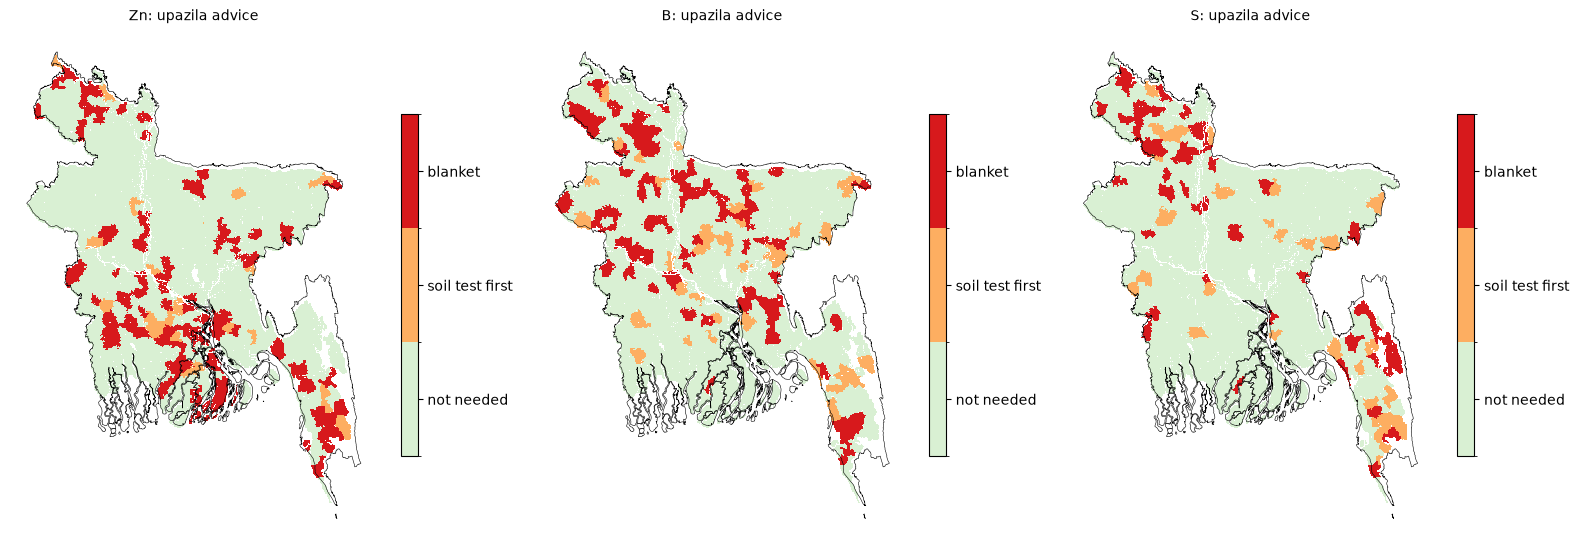

In [20]:
# The same upazila advice, drawn on the 1 km grid
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
amap = {"not needed": 0, "soil test first": 1, "blanket": 2}
cm = ListedColormap(["#d9f0d3", "#fdae61", "#d7191c"])
for ax, t in zip(axes, CL):
    vals = GM["upazila"].map(upz[f"{NAME[t]} advice"]).map(amap)
    sc = ax.scatter(GM["X"] * 1000, GM["Y"] * 1000, c=vals, s=0.6, marker="s", cmap=cm,
                    norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3), linewidths=0)
    cb = plt.colorbar(sc, ax=ax, shrink=0.6, ticks=[0, 1, 2]); cb.ax.set_yticklabels(["not needed", "soil test first", "blanket"])
    base_map(ax, f"{NAME[t]}: upazila advice")
plt.tight_layout(); plt.show()

**Reading the results.**

- **The threshold sets the trade-off.** For Zn, treating where P > 0.5 reaches 66% of the deficient sites while treating 19% of all sites, and 28% of those treatments are not needed. A blanket rule treats every site, and 79% of those treatments are not needed. Lowering the threshold to 0.2 reaches 88% of the deficient sites by treating 33% of all sites.
- **B and S are harder to target.** At P > 0.5, the map reaches 47% of the B-deficient sites and 38% of the S-deficient sites. Their deficiencies are more scattered within upazilas, so a low cost ratio C/L, with its lower threshold, matters more for them.
- **Upazila advice.** Blanket Zn application is indicated in 89 upazilas, B in 74 and S in 49; 28 upazilas qualify for two or more. Most upazilas (346 to 381 of 457) need no blanket application of a given nutrient.
- **Where several deficiencies coincide.** Nilphamari Sadar has the highest expected number of deficiencies (2.3, likely deficient in Zn and S over its whole area and in B over 70%). Chandpur Sadar, Kaharole and Chirirbandar (Dinajpur), Gabtali (Bogura) and Alikadam (Bandarban) follow.
- **Divisions.** Chittagong (57% of area expected deficient in at least one nutrient) and Rajshahi (53%) are most affected. Barisal stands out for Zn (36% of its area), Sylhet has the lowest overall share (32%).

### How certain is the classification?

A probability near 0.5 is the least informative. The map below shows where the deficiency status of Zn, B and S is uncertain (0.3 < P < 0.7), and how that share changes with distance from the nearest sample.

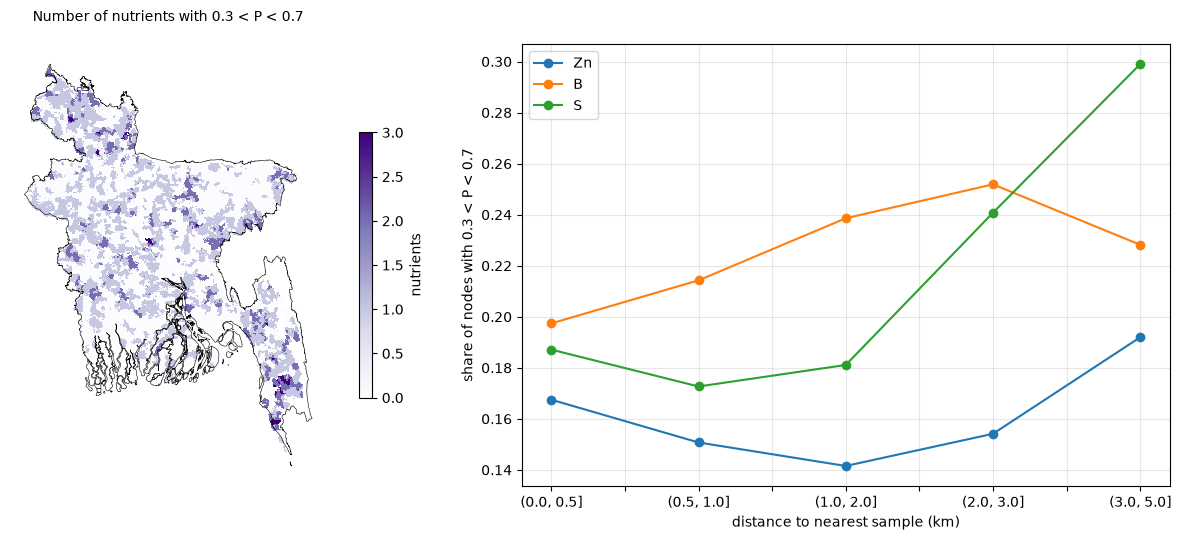

Share of mapped area uncertain: {'Zn': np.float64(0.153), 'B': np.float64(0.22), 'S': np.float64(0.186)}


In [21]:
# A nutrient is uncertain where its probability lies between 0.3 and 0.7
unc = np.column_stack([(GM[f"p_{t}"] > 0.3) & (GM[f"p_{t}"] < 0.7) for t in CL])
GM["n_uncertain"] = unc.sum(1)
# Uncertain nutrients, and whether that band widens away from the nearest sample
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
grid_map(axes[0], GM["n_uncertain"], "Number of nutrients with 0.3 < P < 0.7", cmap="Purples", vmin=0, vmax=3, label="nutrients")
dbin = pd.cut(GM["dist_km"], [0, 0.5, 1, 2, 3, 5])
t_unc = pd.DataFrame({NAME[t]: pd.Series(unc[:, j]).groupby(dbin.to_numpy()).mean() for j, t in enumerate(CL)})
t_unc.plot(ax=axes[1], marker="o"); axes[1].set_xlabel("distance to nearest sample (km)")
axes[1].set_ylabel("share of nodes with 0.3 < P < 0.7")
plt.tight_layout(); plt.show()
print("Share of mapped area uncertain:", {NAME[t]: round(unc[:, j].mean(), 3) for j, t in enumerate(CL)})

**Reading the results.**

- **About a fifth of the area is uncertain for each nutrient.** The probability lies between 0.3 and 0.7 on 15% of the mapped area for Zn, 22% for B and 19% for S. These are the places where a soil test pays most before deciding.
- **Uncertainty depends little on distance.** Because nearly every node is within 2 km of a sample, the share of uncertain nodes changes little with distance, except for S beyond 3 km. The uncertain areas are upazilas where deficient and adequate samples are mixed, which more samples at the same density would not resolve.

## Summary

- **Deficiency is common.** 20.7% of the 37,922 samples are deficient in Zn, 20.7% in B and 17.7% in S (30.7% with the FRG 2018 level of 14 µg/g), and 47.7% in at least one of them. Zn deficiency follows high pH in the Ganges and Meghna floodplains; B and S deficiency follow low organic matter in the north and northwest.
- **The survey unit leaves a mark.** Samples 1 km apart across an upazila boundary differ almost as much as random pairs, and up to two thirds of the variance of log Zn lies between upazila means. The indicator variograms have a short practical range (about 30 km) and a large nugget.
- **The best estimator uses that structure.** Indicator kriging restricted to each upazila has the highest skill (Zn: BSS 0.50, AUC 0.93 in random cross-validation), followed closely by the upazila mean. Plain IK and random forests with landscape attributes are less skilful. No estimator predicts an unsampled district.
- **Maps.** P > 0.5 covers 17% of the mapped area for Zn and for B and 11% for S, and 47% for at least one of the three. Single deficiencies dominate.
- **Advice.** Blanket application is indicated in 89 upazilas for Zn, 74 for B and 49 for S, and soil testing first in another 20 to 37 per nutrient.
- **Coordinates.** The sample and grid coordinates were identified as Kalianpur 1975 / India zone IIb with a shifted false origin, and transformed to BUTM to within 10 m.

### Limitations

- **Unknown survey details.** The year, extraction method and laboratory of each sample are not in the data. The upazila effect in Section 3.2 shows that they matter, but it cannot be separated from real differences between upazilas without them.
- **Critical levels.** One critical level per nutrient is used for all crops and soils. Field studies in Bangladesh report crop-specific levels, for example 0.73 to 0.85 µg/g Zn for rice and potato on floodplain soils (Rahman et al., 2022).
- **Rounded values.** Values are reported to 0.1 µg/g (Zn, B) or 1 µg/g (S), and many samples sit exactly at a critical level, so small changes in the level change the share deficient a lot.
- **Upazila assignment.** Grid nodes take the upazila of their nearest sample, which approximates the boundaries. The upazila polygons would remove this approximation.
- **Coarse covariates.** The landscape attributes are categorical maps at 1:250,000 or coarser. They explain the broad pattern but not the field-to-field variation that decides deficiency.
- **Probabilities, not areas.** Area shares are sums of marginal probabilities. Their uncertainty would need sequential indicator simulation (`sisim`), as in Capstone 1.

### Exercises

1. Repeat the analysis with the FRG 2018 critical level for S (14 µg/g). How many upazilas change advisory class?
2. Krige pH and organic matter first and add them as covariates of the RF + SK estimator. Does skill at 10 and 25 km improve?
3. Add an upazila random effect to the random forest (for example, the out-of-fold upazila mean as a feature) and compare with IK within upazila.
4. Run `sisim` for Zn deficiency in one division and give a 90% interval for its deficient area.
5. Use the remote-sensing covariates in `BD_Data/Raster` (NDVI, NDFI, LAI, PET) and test whether they add skill beyond the landscape attributes.
6. Choose a cost ratio C/L for zinc sulphate on rice and map where application pays.

## References

- Bangladesh Agricultural Research Council (2018). *Fertilizer Recommendation Guide 2018.* BARC, Dhaka.
- Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation.* Oxford University Press.
- Hengl, T., Nussbaum, M., Wright, M. N., Heuvelink, G. B. M. and Gräler, B. (2018). Random forest as a generic framework for predictive modeling of spatial and spatio-temporal variables. *PeerJ*, 6, e5518.
- Naher, M. S., Rahman, M. A., Islam, M. A., Alam, M. A. and Choudhury, M. N. A. (2024). Impact of sulfur levels on the growth and yield of winter onion in Level Barind Tract of Bangladesh. *Bangladesh Journal of Agricultural Research*, 49(3), 293-303.
- Rahman, M., Jahangir, M. M. R., Kibria, M. G., Hossain, M., Hosenuzzaman, M., Solaiman, Z. M. and Abedin, M. A. (2022). Determination of critical limit of zinc for rice (*Oryza sativa* L.) and potato (*Solanum tuberosum* L.) cultivation in floodplain soils of Bangladesh. *Sustainability*, 14(1), 167.
- Sultana, S., Naser, H. M. and Akhter, S. (2016). Effectiveness of soil and foliar applications of zinc and boron on the yield of tomato. *Bangladesh Journal of Agricultural Research*, 41(3), 411-418.